In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR_HMA_evaluation_paper/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import numpy.ma as ma
from scipy import stats
from matplotlib.lines import Line2D
from pyproj import Transformer

In [2]:
'''
Precip_v1.xls
Excel file with a Precip sheet containing monthly precipitation sums by station and year, 
and a Info_prec sheet containing information about each record including start 
and end year and percentage complete. The format is the same as for Taver_v1.xls.'''

'\nPrecip_v1.xls\nExcel file with a Precip sheet containing monthly precipitation sums by station and year, \nand a Info_prec sheet containing information about each record including start \nand end year and percentage complete. The format is the same as for Taver_v1.xls.'

In [3]:
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/stations_central_asia/'
fileCentralAsia='Precip_v1_1.txt'

In [4]:
df_all_stations = pd.read_csv(sourceData+fileCentralAsia, sep="\t") 
#df_all_stations

In [5]:
station_check = df_all_stations.groupby('Code_WMO')['Name'].nunique()
#station_check

In [6]:
duplicates = station_check[station_check > 1]
#print(duplicates)

In [7]:
print(df_all_stations[df_all_stations['Code_WMO'] == 35796][['Code_WMO','Name', 'Long', 'Lat', 'Alt']].drop_duplicates()
)

      Code_WMO     Name   Long    Lat  Alt
385    35796.0  Balhash  75.00  46.90  398
449    35796.0  Balhash  75.08  46.80  398
1856   35796.0   Kuigan  74.20  45.38  345


In [8]:
###There are some WMO code with two different names, need to check is it is just a name change or an errror?
##For the moment I remove them

In [9]:
# First, ensure Code_WMO is numeric and drop NaNs for analysis
df_valid_codes = df_all_stations[df_all_stations['Code_WMO'].notna()].copy()

# Remove the duplicates (as before)
station_check = df_valid_codes.groupby('Code_WMO')['Name'].nunique()
duplicates = station_check[station_check > 1].index.tolist()

# Remove all rows with these duplicated WMO codes
df_clean = df_all_stations[~df_all_stations['Code_WMO'].isin(duplicates)].copy()

# Final check
#print("Original rows:", len(df_all_stations))
#print("Rows after removing duplicates:",len(df_clean))


In [10]:
## Model MAR
domain='GRp'
sourceDataGrid='/home/santolam/'
fileName_grF='NST.2014.01.01.00.GRi.nc'
#fileName_grM='NST.2000.01.01.00.GRa_Mera.nc_ICEmask'
dsF= xr.open_dataset(sourceDataGrid+fileName_grF) ## Year mean?
print('lon min',dsF.LON.values.min(),'lon max',dsF.LON.values.max())
print('lat min',dsF.LAT.values.min(),'lat max',dsF.LAT.values.max())

lon_min, lon_max =dsF.LON.values.min(),dsF.LON.values.max()
lat_min, lat_max= dsF.LAT.values.min(),dsF.LAT.values.max()
print(lon_min,lon_max)
print(lat_min,lat_max)

lon min 6.7526566e+01 lon max 77.156975
lat min 36.19467 lat max 41.38051
67.526566 77.156975
36.19467 41.38051


In [11]:
df_dom= df_clean[
    (df_clean['Long'] >= lon_min) & (df_clean['Long'] <= lon_max) &
    (df_clean['Lat'] >= lat_min) & (df_clean['Lat'] <= lat_max)
]

In [12]:
df_dom[0:5]

,Country,Code_WMO,Name,Long,Lat,Alt,Years,I,II,III,IV,V,VI,VII,VIII,IX,X,XI,XII
3650,213,36992.0,Aksai,72.83,40.05,3135,1952,1.5,7.9,10.8,33.2,44.5,31.6,44.8,25.3,33.9,0.9,2.7,2.8
3651,213,36992.0,Aksai,72.83,40.05,3135,1953,4.4,5.9,26.7,17.5,46.1,48.8,45.1,39.7,43.3,33.2,21.3,18.6
3652,213,36992.0,Aksai,72.83,40.05,3135,1954,7.2,3.4,5.3,28.2,24.2,45.6,58.6,85.4,15,2.0,2.7,3.9
3653,213,36992.0,Aksai,72.83,40.05,3135,1955,1.5,3,24.3,9.6,24.8,31,21.3,27.5,28.3,5.4,0.3,12
3654,213,36992.0,Aksai,72.83,40.05,3135,1956,3.6,17.2,16.3,28.1,21.1,66.9,3.5,22.0,17.4,5.2,1.1,3


In [13]:
# Replace -999.0 (missing value) with NaN
df = df_dom.replace(-999.0, pd.NA)

# List of month column names
month_cols = ['I', 'II', 'III', 'IV', 'V', 'VI', 'VII', 'VIII', 'IX', 'X', 'XI', 'XII']

df[month_cols] = df[month_cols].apply(pd.to_numeric, errors='coerce') #if not I have an error, they are strings
df.replace(-999.0, np.nan, inplace=True)


df['DJF'] = (df['XII'].shift(1) + df['I'] + df['II']) / 3 # DJF: Dec (from previous year), Jan, Feb
df['MAM'] = (df['III'] + df['IV'] + df['V']) / 3
df['JJA'] = (df['VI'] + df['VII'] + df['VIII']) / 3
df['SON'] = (df['IX'] + df['X'] + df['XI']) / 3
df['Annual'] = df[month_cols].mean(axis=1, skipna=True)

# Now include it in your seasonal_means DataFrame
seasonal_means = df[['Code_WMO', 'Name', 'Long', 'Lat', 'Alt', 'Years', 
                     'DJF', 'MAM', 'JJA', 'SON', 'Annual']]
#stations_list=[]
grouped = seasonal_means.groupby('Code_WMO')

stations_dict = {}
for wmo_code, group in grouped:
    group = group.reset_index(drop=True)
    #stations_list.append(group)  # for iteration
    stations_dict[wmo_code] = group.set_index('Years')  # for direct lookup and time series


In [14]:
#print(len(seasonal_means))

In [15]:
#print(seasonal_means[0:5])

In [16]:
ann_clim = (
    seasonal_means
    .groupby(['Code_WMO', 'Name', 'Long', 'Lat', 'Alt'], as_index=False)
    .agg(
        iyear=('Years', 'min'),
        fyear=('Years', 'max'),
        ann_mean=('Annual', 'mean')
    )
)

In [17]:
ann_clim

,Code_WMO,Name,Long,Lat,Alt,iyear,fyear,ann_mean
0,36969.0,Atbashi,75.80,41.20,2025,1927,1995,24.326983
1,36992.0,Aksai,72.83,40.05,3135,1952,1998,22.594504
2,36994.0,Chatirkul,75.80,40.60,3540,1961,1990,20.405152
3,38447.0,Kaunchi,69.00,41.08,340,1927,1999,27.604412
4,38457.0,Tashkent,69.30,41.33,477,1877,2001,32.710333
...,...,...,...,...,...,...,...,...
71,38937.0,Shaartuz,68.13,37.28,380,1943,1990,12.973027
72,38947.0,Nizhniy Pyandge,68.58,37.20,329,1947,1990,14.787470
73,38951.0,Rushan,71.52,37.95,1966,1947,1990,21.171212
74,38956.0,Dzhavshangoz,72.46,37.36,3576,1935,1990,11.705035


In [18]:
#station_info['Long'].values

In [19]:

lat_stas =ann_clim['Lat'].values   #extract_column_float(data_dicts, 'Lat')
lon_stas = ann_clim['Long'].values 
elev_stas= ann_clim['Alt'].values 
codes =ann_clim['Code_WMO'].values

lon_MAR=dsF.LON;lat_MAR=dsF.LAT
iMAR_sta=[];jMAR_sta=[] ##coord of MAR pixel corresponding to station location

for pos in np.arange(len(lat_stas)):
    target_lon,target_lat=float(lon_stas[pos]),float(lat_stas[pos])
    # Compute distance to each grid point
    dist = np.sqrt((lon_MAR - target_lon)**2 + (lat_MAR - target_lat)**2)
    j, i = np.unravel_index(dist.argmin(), dist.shape) 
    jMAR_sta.append(j);iMAR_sta.append(i)

In [20]:
##Comparison of elevation (for example) at one point
SH_MAR_sta=dsF.SH[jMAR_sta[0],iMAR_sta[0]]
dif=elev_stas[0]-SH_MAR_sta.values
#print(dif)

In [21]:

##For all points
SHList_dom=[];LONList_dom=[];LATList_dom=[]
for k in range(len(jMAR_sta)):
    tmp=dsF.SH[jMAR_sta[k],iMAR_sta[k]]
    SHList_dom.append(tmp)
    tmp1=dsF.LON[jMAR_sta[k],iMAR_sta[k]]
    LONList_dom.append(tmp1)
    tmp2=dsF.LAT[jMAR_sta[k],iMAR_sta[k]]
    LATList_dom.append(tmp2)


In [22]:
ds_stations_MARgrid= [{
    'codes_wmo':int(codes[i]),
    'lat_sta_ori': lat_stas[i],
    'lon_sta_ori':lon_stas[i],
    'elev_station_ori': elev_stas[i],
    'pix_i_sta_mar':iMAR_sta[i], ## coord i,j: Position of station in the pixel of MAR grid (the closest)
    'pix_j_sta_mar':jMAR_sta[i], ## coord i,j: Position of station in the pixel of MAR grid (the closest)
    'elev_MAR_pix': SHList_dom[i].values,
    'lat_mar':LATList_dom[i].values, #Same as pix i,j to test that it it the same point
    'lon_mar':LONList_dom[i].values
} for i in range(len(SHList_dom))]


df_stations_MARgrid= pd.DataFrame(ds_stations_MARgrid)


In [23]:
#print(len(df_stations_MARgrid['elev_MAR_pix']))

In [24]:
df_stations_MARgrid[0:5]

,codes_wmo,lat_sta_ori,lon_sta_ori,elev_station_ori,pix_i_sta_mar,pix_j_sta_mar,elev_MAR_pix,lat_mar,lon_mar
0,36969,41.20,75.80,2025,99,79,2652.819,41.20258,75.81277
1,36992,40.05,72.83,3135,63,60,3466.3733,40.057922,72.79341
2,36994,40.60,75.80,3540,99,69,3680.7898,40.574116,75.78022
3,38447,41.08,69.00,340,17,77,330.42392,41.081726,68.96056
4,38457,41.33,69.30,477,21,81,514.09454,41.34211,69.28284


In [25]:
len(df_stations_MARgrid['elev_MAR_pix'])

76

In [26]:
##PRECIP comparison

In [27]:
domainM='GRp'; nx=ny=10
ds_RF_raw=xr.open_mfdataset('/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/GRp/spin2/work/monthly/'+
    'RF_monsum_MARv3.14_ER5_spin2_GRp_*.nc')['RF']#.sel(ZTQLEV=2)
ds_RF= ds_RF_raw.rename({'TIME': 'time'})
ds_RF=ds_RF#[:,ny:-ny,nx:-nx]

ds_SF_raw=xr.open_mfdataset('/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/GRp/spin2/work/monthly/'+
    'SF_monsum_MARv3.14_ER5_spin2_GRp_*.nc')['SF']#.sel(ZTQLEV=2)
ds_SF= ds_SF_raw.rename({'TIME': 'time'})
ds_SF=ds_SF#[#:,ny:-ny,nx:-nx]

In [28]:
ds_TF=ds_RF+ds_SF
#vals,anoms=climb.seasonal_selection(ds_TF,'DJF',1980,2024)
iyr,fyr=1950,1990
#ds_TTZ=ds_TTZ.sel(time=slice("1950",fyr))
ds_TF = ds_TF.sel(time=slice("1950-01-01", f"{fyr}-12-31"))

vals,anoms=climb.seasonal_selection(ds_TF,'JFMAMJJASOND',iyr,fyr)
#vals.time

In [29]:
df_stations_MARgrid[0:5]

,codes_wmo,lat_sta_ori,lon_sta_ori,elev_station_ori,pix_i_sta_mar,pix_j_sta_mar,elev_MAR_pix,lat_mar,lon_mar
0,36969,41.20,75.80,2025,99,79,2652.819,41.20258,75.81277
1,36992,40.05,72.83,3135,63,60,3466.3733,40.057922,72.79341
2,36994,40.60,75.80,3540,99,69,3680.7898,40.574116,75.78022
3,38447,41.08,69.00,340,17,77,330.42392,41.081726,68.96056
4,38457,41.33,69.30,477,21,81,514.09454,41.34211,69.28284


In [30]:
print(dsF.SH.shape)

(82, 116)


In [31]:
ts_mar = vals.isel(Y=j, X=i)

In [32]:
mar_rows = []

for _, row in df_stations_MARgrid.iterrows():
    
    code = int(row.codes_wmo)
    i = int(row.pix_i_sta_mar)
    j = int(row.pix_j_sta_mar)

    # Extract MAR annual time series for this station
    #ts_mar = vals[:, j, i]  # time dimension already annual
    ts_mar = vals.isel(Y=j, X=i)
    mar_df = pd.DataFrame({
        'Code_WMO': code,
        'Years': ts_mar.time.values.astype(int),
        'MAR_Annual': ts_mar.values
    })

    mar_rows.append(mar_df)

df_mar_ann = pd.concat(mar_rows, ignore_index=True)

In [33]:
df_mar_ann

,Code_WMO,Years,MAR_Annual
0,36969,1950,1.070477
1,36969,1951,1.350200
2,36969,1952,0.900276
3,36969,1953,1.635111
4,36969,1954,1.137503
...,...,...,...
3111,38957,1986,15.478889
3112,38957,1987,15.001227
3113,38957,1988,8.187821
3114,38957,1989,6.061211


In [34]:
rows = []

for _, row in df_stations_MARgrid.iterrows():

    code = int(row.codes_wmo)

    # --- station obs (annual)
    sta = stations_dict[code]
    sta_years = sta.index.astype(int)
    sta_ann = sta['Annual']

    # --- MAR time series at station pixel
    ts_mar = vals[:, row.pix_j_sta_mar, row.pix_i_sta_mar]
    mar_years = ts_mar.time.values.astype(int)

    # --- common period
    iyear = max(sta_years.min(), mar_years.min())
    fyear = min(sta_years.max(), mar_years.max())

    if iyear > fyear:
        continue  # no overlap

    sta_c = sta_ann.loc[iyear:fyear]
    mar_c = ts_mar.sel(time=slice(iyear, fyear))

    # --- climatological means
    rows.append({
        'Code_WMO': code,
        'iyear': iyear,
        'fyear': fyear,
        'ann_mean_obs': sta_c.mean(),
        'ann_mean_MAR': mar_c.mean().item(),
        'bias_MAR-sta': mar_c.mean().item() - sta_c.mean(),
        'elev_sta': row.elev_station_ori,
        'elev_MAR_pix': row.elev_MAR_pix
    })

df_clim_MAR = pd.DataFrame(rows)


In [35]:
df_clim_MAR 

,Code_WMO,iyear,fyear,ann_mean_obs,ann_mean_MAR,bias_MAR-sta,elev_sta,elev_MAR_pix
0,36969,1950,1990,24.722154,1.547808,-23.174346,2025,2652.819
1,36992,1952,1990,22.485684,44.838775,22.353092,3135,3466.3733
2,36994,1961,1990,20.405152,16.712733,-3.692419,3540,3680.7898
3,38447,1950,1990,28.619206,0.571118,-28.048087,340,330.42392
4,38457,1950,1990,34.915244,0.000000,-34.915244,477,514.09454
...,...,...,...,...,...,...,...,...
71,38937,1950,1990,13.320089,0.003998,-13.316091,380,469.96008
72,38947,1950,1990,15.199196,0.194651,-15.004545,329,378.977
73,38951,1950,1990,21.010976,1.681948,-19.329027,1966,2630.3953
74,38956,1950,1990,11.711936,7.395488,-4.316449,3576,3842.2993


In [36]:
#ds_TF

In [37]:
import pandas as pd

records = []

for _, row in df_stations_MARgrid.iterrows():

    wmo = int(row["codes_wmo"])
    iy  = int(row["pix_j_sta_mar"])
    ix  = int(row["pix_i_sta_mar"])

    # Extract model precipitation at that grid point
    da_sta = ds_TF.isel(Y=iy, X=ix).rename("TF")
    df = da_sta.to_dataframe().reset_index()
    # Convert to DataFrame

    # Add station / model metadata
    df["Code_WMO"] = wmo
    df["Lat"]      = row["lat_mar"]
    df["Long"]     = row["lon_mar"]
    df["Alt"]      = row["elev_MAR_pix"]

    records.append(df)

df_model_long = pd.concat(records, ignore_index=True)


In [38]:
#df_model_long

In [39]:
df_model_long["Years"] = df_model_long["time"].dt.year
df_model_long["Month"] = df_model_long["time"].dt.month


In [40]:
#df_model_long

In [41]:
df_model_wide = (
    df_model_long
    .pivot_table(
        index=["Code_WMO", "Lat", "Long", "Alt", "Years"],
        columns="Month",
        values="TF",
        aggfunc="mean"   # monthly mean or sum, adjust if needed
    )
    .reset_index()
)

In [42]:
#df_model_wide

In [43]:
month_map = {
    1: "I", 2: "II", 3: "III", 4: "IV",
    5: "V", 6: "VI", 7: "VII", 8: "VIII",
    9: "IX", 10: "X", 11: "XI", 12: "XII"
}

df_model_wide = df_model_wide.rename(columns=month_map)


In [44]:
df_model_wide["Country"] = None
df_model_wide["Name"]    = "MAR_grid"

cols = [
    "Country", "Code_WMO", "Name",
    "Long", "Lat", "Alt", "Years",
    "I", "II", "III", "IV", "V", "VI",
    "VII", "VIII", "IX", "X", "XI", "XII"
]

df_model_final = df_model_wide[cols]


In [45]:
#df_model_final[0:4]

In [46]:
#df_dom[0:4]

In [47]:
months = ["I","II","III","IV","V","VI","VII","VIII","IX","X","XI","XII"]

df_dom_clean = df_dom.copy()
df_dom_clean[months] = df_dom_clean[months].replace(-999.0, np.nan)

In [48]:
df_dom_clean = df_dom.copy()
df_dom_clean[months] = df_dom_clean[months].apply(pd.to_numeric, errors="coerce")
df_dom_clean[months] = df_dom_clean[months].replace(-999.0, np.nan)
#

In [49]:
df_dom_clean.min()

Country                 213
Code_WMO            36969.0
Name        Abramov Glacier
Long                  67.58
Lat                   36.73
Alt                     248
Years                  1877
I                       0.0
II                      0.0
III                     0.0
IV                      0.0
V                       0.0
VI                      0.0
VII                     0.0
VIII                    0.0
IX                      0.0
X                       0.0
XI                      0.0
XII                     0.0
dtype: object

In [50]:
import numpy as np
def monthly_bias_common_period(df_obs, df_mar, wmo):
    """
    Returns a DataFrame with monthly climatological bias (MAR - OBS)
    and relative bias (%) computed over the common years only, with the number of years.
    """

    obs = df_obs[df_obs["Code_WMO"] == wmo]
    mar = df_mar[df_mar["Code_WMO"] == wmo]

    # Common years
    common_years = np.intersect1d(obs["Years"], mar["Years"])
    
    n_years = len(common_years)  # number of years used for climatology

    if n_years == 0:
        return None

    obs_c = obs[obs["Years"].isin(common_years)]
    mar_c = mar[mar["Years"].isin(common_years)]
    alt = obs_c["Alt"].iloc[0] if "Alt" in obs_c.columns else mar_c["Alt"].iloc[0]

    data = []

    for m in months:
        obs_mean = pd.to_numeric(obs_c[m], errors="coerce").mean()
        mar_mean = pd.to_numeric(mar_c[m], errors="coerce").mean()
        bias = mar_mean - obs_mean
        rel_bias = (bias / obs_mean * 100) if obs_mean != 0 else np.nan  # avoid division by zero

        data.append({
            "Code_WMO": wmo,
            "Month": m,
            "OBS": obs_mean,
            "MAR": mar_mean,
            "Bias": bias,
            "Rel_Bias": rel_bias,
            "N_years": n_years,
            "Alt": alt,
            "common_years": common_years  
        })

    return pd.DataFrame(data)


In [51]:
bias_list = []

common_stations = set(df_dom_clean["Code_WMO"]).intersection(
    set(df_model_final["Code_WMO"])
)

for wmo in common_stations:
    df_b = monthly_bias_common_period(df_dom_clean, df_model_final, wmo)
    if df_b is not None:
        bias_list.append(df_b)

df_bias_monthly = pd.concat(bias_list, ignore_index=True)


In [52]:
#df_bias_monthly

In [53]:
#months = ["I","II","III","IV","V","VI","VII","VIII","IX","X","XI","XII"]

# Pivot bias to station x month
bias_mat = (
    df_bias_monthly
    .pivot(index="Code_WMO", columns="Month", values="Bias")
    .reindex(columns=months)
)

rbias_mat = (
    df_bias_monthly
    .pivot(index="Code_WMO", columns="Month", values="Rel_Bias")
    .reindex(columns=months)
)

# Get station metadata: Altitude and number of years
station_meta = (
    df_bias_monthly
    .drop_duplicates("Code_WMO")
    .set_index("Code_WMO")[["Alt", "N_years","common_years"]]
)

# Order stations by elevation (low -> high)
station_order = station_meta["Alt"].sort_values().index
bias_mat = bias_mat.loc[station_order]
station_meta = station_meta.loc[station_order]

# y-axis labels: WMO (alt m)
#ylabels = [
#    f"{int(wmo)} ({int(alt)} m)"
#    for wmo, alt in zip(station_meta.index, station_meta["Alt"])
#]
ylabels = [
    f"{int(alt)}"
    for alt in station_meta["Alt"]]

# Right y-axis values: number of years
n_years = station_meta["N_years"].values
#iyr="common_years":common_years,

In [54]:
station_meta["common_years"]

Code_WMO
38583    [1961, 1962, 1963, 1964, 1965, 1966, 1967, 196...
38586    [1957, 1958, 1959, 1960, 1961, 1962, 1963, 196...
38697    [1950, 1951, 1952, 1953, 1954, 1955, 1956, 195...
38594    [1950, 1951, 1952, 1953, 1954, 1955, 1956, 195...
38597    [1951, 1952, 1953, 1954, 1955, 1956, 1957, 195...
                               ...                        
36994    [1961, 1962, 1963, 1964, 1965, 1966, 1967, 196...
38956    [1950, 1951, 1952, 1953, 1954, 1955, 1956, 195...
38707    [1967, 1968, 1969, 1970, 1971, 1972, 1973, 197...
38871    [1950, 1951, 1952, 1953, 1954, 1955, 1956, 195...
38862    [1950, 1951, 1952, 1953, 1954, 1955, 1956, 195...
Name: common_years, Length: 76, dtype: object

In [55]:
station_meta["year_start"] = station_meta["common_years"].apply(lambda x: x[0] if len(x) > 0 else np.nan)
station_meta["year_end"]   = station_meta["common_years"].apply(lambda x: x[-1] if len(x) > 0 else np.nan)

# Check result
station_meta[["year_start", "year_end"]].head()

,year_start,year_end
Code_WMO,,
38583,1961,1990
38586,1957,1990
38697,1950,1990
38594,1950,1990
38597,1951,1990


In [56]:
fyr=station_meta["year_end"] 
#print(n_years+1980)


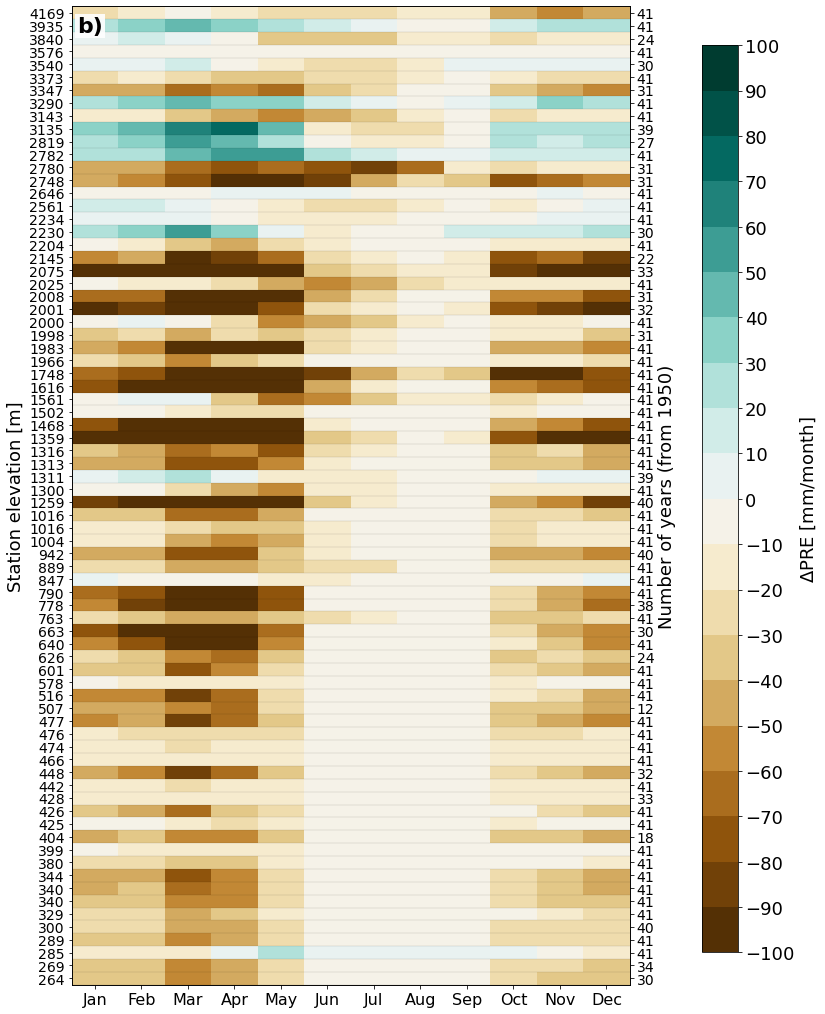

In [57]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

Z = bias_mat.values #(station × month)
# ylabels = ["WMO (alt m)", ...]
# n_years = array/list of number of years for each station, same order as ylabels

# Define discrete intervals for the bias (mm)
bounds = np.arange(-100, 110, 10)  # adjust according to your data
cmap = plt.get_cmap("BrBG", len(bounds)-1)  # discrete BrBG
norm = mcolors.BoundaryNorm(bounds, cmap.N)

# Grid for pcolormesh
x = np.arange(len(months) + 1)
y = np.arange(len(ylabels) + 1)

fig, ax = plt.subplots(figsize=(10, 18))

# Plot bias
pcm = ax.pcolormesh(
    x, y, Z,
    cmap=cmap,
    norm=norm,
    shading="auto"
)

# Horizontal lines for each station
for yy in range(len(ylabels)):
    ax.axhline(yy, color="k", lw=0.3, alpha=0.3)

# Left y-axis: WMO + elevation
ax.set_yticks(np.arange(len(ylabels)) + 0.5)
ax.set_yticklabels(ylabels)
ax.set_ylabel("Station elevation [m]",fontsize=18)

# Right y-axis: number of years
ax2 = ax.twinx()
ax2.set_ylim(ax.get_ylim())  # align with left y-axis
ax2.set_yticks(np.arange(len(ylabels)) + 0.5)
ax2.set_yticklabels(n_years)  # n_years in same order as ylabels
ax2.set_ylabel("Number of years (from 1950)",fontsize=18)

# X-axis
ax.set_xticks(np.arange(len(months)) + 0.5)
ax.set_xticklabels(months)
#ax.set_xlabel("Month", fontsize=18)

ax.tick_params(axis="x", labelsize=16)
ax.tick_params(axis="y", labelsize=14)
ax2.tick_params(axis="y", labelsize=14)
#ax2.tick_params(axis="y", labelsize=16)

cbar_ax = fig.add_axes([1., 0.15, 0.05, 0.7])  # [left, bottom, width, height] in figure coords
cbar = fig.colorbar(pcm, cax=cbar_ax, orientation='vertical', ticks=bounds)
cbar.set_label("$\Delta$PRE [mm/month]", fontsize=18)
cbar.ax.tick_params(labelsize=18)

ax.text(
    0.01, 0.99,            # position relative à l'axe
    'b)',
    transform=ax.transAxes,
    fontsize=22,
    fontweight='bold',
    va='top',
    ha='left',
    bbox=dict(facecolor='white', edgecolor='none', alpha=0.9, pad=2)
)

#plt.tight_layout()
#plotsDir = "/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
#plotsDir='/home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/'
#plotname = f"FIG11b_elevation_annual_cycle_bias_central_asia_pre.{domain}_SH_ICE_pamir_rev1_Fanny1990"

#plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
#print(f"Saved: {plotsDir}{plotname}.png")

plt.show()


In [58]:
'''
months = ["I","II","III","IV","V","VI","VII","VIII","IX","X","XI","XII"]

# Select station
obs_sta = df_dom_clean.query("Code_WMO == @wmo")
mar_sta = df_model_final.query("Code_WMO == @wmo")

# ---- Common period ----
start_year = max(obs_sta["Years"].min(), mar_sta["Years"].min())
end_year   = min(obs_sta["Years"].max(), mar_sta["Years"].max())

obs_sta_cp = obs_sta.query("@start_year <= Years <= @end_year")
mar_sta_cp = mar_sta.query("@start_year <= Years <= @end_year")

# ---- Monthly climatology over common period ----
obs_mean = obs_sta_cp[months].astype(float).mean(axis=0)
mar_mean = mar_sta_cp[months].astype(float).mean(axis=0)

df_compare = pd.DataFrame({
    "Month": months,
    "OBS": obs_mean.values,
    "MAR": mar_mean.values
})
df_compare["Bias"] = df_compare["MAR"] - df_compare["OBS"]

# ---- Plot ----
plt.figure(figsize=(8,4))
plt.plot(months, df_compare["OBS"], marker="o", label="OBS")
plt.plot(months, df_compare["MAR"], marker="o", label="MAR")

plt.title(f"WMO {wmo} – Climatology ({start_year}–{end_year})")
plt.ylabel("Monthly precipitation (mm)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
'''

'\nmonths = ["I","II","III","IV","V","VI","VII","VIII","IX","X","XI","XII"]\n\n# Select station\nobs_sta = df_dom_clean.query("Code_WMO == @wmo")\nmar_sta = df_model_final.query("Code_WMO == @wmo")\n\n# ---- Common period ----\nstart_year = max(obs_sta["Years"].min(), mar_sta["Years"].min())\nend_year   = min(obs_sta["Years"].max(), mar_sta["Years"].max())\n\nobs_sta_cp = obs_sta.query("@start_year <= Years <= @end_year")\nmar_sta_cp = mar_sta.query("@start_year <= Years <= @end_year")\n\n# ---- Monthly climatology over common period ----\nobs_mean = obs_sta_cp[months].astype(float).mean(axis=0)\nmar_mean = mar_sta_cp[months].astype(float).mean(axis=0)\n\ndf_compare = pd.DataFrame({\n    "Month": months,\n    "OBS": obs_mean.values,\n    "MAR": mar_mean.values\n})\ndf_compare["Bias"] = df_compare["MAR"] - df_compare["OBS"]\n\n# ---- Plot ----\nplt.figure(figsize=(8,4))\nplt.plot(months, df_compare["OBS"], marker="o", label="OBS")\nplt.plot(months, df_compare["MAR"], marker="o", label="

In [59]:
#obs_sta 